# 15 Named Entity Recognition

Menandai nama orang, tempat, dan organisasi. Contoh: dataset NERGrit.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Mengenali nama entitas |
| **Unit prediksi** | Tiap kata mendapat label BIO |
| **Metrik** | F1 tingkat span |
| **Masalah terbesar** | Batas dan jenis entitas harus tepat, 11,7% kata test tidak pernah muncul di latih, dan data latih hanya 1.672 kalimat. |
| **Data contoh** | NERGrit: PERSON, PLACE, ORGANISATION |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta mengambil entitas dari teks, misalnya lembaga, daerah, atau tokoh di berita MBG. Metriknya biasanya span F1.

**Yang perlu diganti kalau datanya beda:**
- `DATA_FOLDER`, atau `read_conll` kalau formatnya bukan satu token per baris.
- `MODEL_RUNS` di config. `indobert` untuk teks formal, `indobertweet` untuk media sosial.
- Kalau label bukan pola BIO, ganti metrik di bagian 6 dengan akurasi token.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya baseline fitur per token, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
DATA_FOLDER = "nergrit_ner-grit"

SETTINGS = {
    "cepat": {"epochs": 3, "model_runs": [("indobert", SEED)]},
    "penuh": {
        "epochs": 6,
        "model_runs": [("indobert", SEED), ("indobert", SEED + 1), ("indobert", SEED + 2)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 6, 'model_runs': [('indobert', 42), ('indobert', 43), ('indobert', 44)]}


**Data format per token.** `read_conll` membaca file satu token per baris dengan label di kolom kedua,
dan kalimat dipisah baris kosong.

In [5]:
def read_conll(path: Path) -> list[tuple[list[str], list[str]]]:
    """Kembalikan daftar (token, label) per kalimat."""
    sentences, tokens, tags = [], [], []
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            if tokens:
                sentences.append((tokens, tags))
            tokens, tags = [], []
            continue
        parts = line.split("\t")
        tokens.append(parts[0])
        tags.append(parts[-1])
    if tokens:
        sentences.append((tokens, tags))
    return sentences

**Metrik tingkat span.** Satu entitas dianggap benar kalau batas dan jenisnya tepat. Ini standar seqeval,
dan ditulis sendiri supaya tidak butuh library tambahan.

In [6]:
def extract_spans(tags: list[str]) -> set[tuple[int, int, str]]:
    """Ubah label BIO menjadi himpunan (mulai, selesai, jenis)."""
    spans, start, kind = set(), None, None
    for i, tag in enumerate(list(tags) + ["O"]):
        prefix, _, name = tag.partition("-")
        if prefix in ("B", "O") or (prefix == "I" and name != kind):
            if start is not None:
                spans.add((start, i, kind))
            start, kind = (i, name) if prefix != "O" else (None, None)
    return spans


def span_scores(true_seqs, pred_seqs) -> dict[str, float]:
    """Precision, recall, dan F1 span secara mikro."""
    tp = fp = fn = 0
    for true_tags, pred_tags in zip(true_seqs, pred_seqs):
        true_spans, pred_spans = extract_spans(true_tags), extract_spans(pred_tags)
        tp += len(true_spans & pred_spans)
        fp += len(pred_spans - true_spans)
        fn += len(true_spans - pred_spans)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(2 * precision * recall / max(precision + recall, 1e-9), 4),
    }


assert extract_spans(["B-A", "I-A", "O", "B-B"]) == {(0, 2, "A"), (3, 4, "B")}
assert span_scores([["B-A", "I-A", "O"]], [["B-A", "I-A", "O"]])["f1"] == 1.0
assert span_scores([["B-A", "I-A", "O"]], [["B-A", "O", "O"]])["f1"] == 0.0

**Baseline CRF-lite.** Regresi logistik per token dengan fitur kata, sufiks, bentuk, dan kata tetangga.
Tidak butuh model dari luar, jadi jadi cadangan kalau pretrained dilarang.

In [7]:
from sklearn.feature_extraction import DictVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression as TokenLR  # noqa: E402


def token_features(tokens: list[str], i: int) -> dict:
    word = tokens[i]
    return {
        "w": word.lower(),
        "suf3": word[-3:].lower(),
        "pre3": word[:3].lower(),
        "title": word.istitle(),
        "upper": word.isupper(),
        "digit": word.isdigit(),
        "prev": tokens[i - 1].lower() if i else "<s>",
        "next": tokens[i + 1].lower() if i + 1 < len(tokens) else "</s>",
    }


def token_baseline(train_sents, predict_sents):
    """Latih di token, prediksi per kalimat."""
    x_train = [token_features(s[0], i) for s in train_sents for i in range(len(s[0]))]
    y_train = [t for s in train_sents for t in s[1]]
    vectorizer = DictVectorizer()
    model = TokenLR(max_iter=300, C=3.0)
    model.fit(vectorizer.fit_transform(x_train), y_train)
    output = []
    for tokens, _ in predict_sents:
        features = [token_features(tokens, i) for i in range(len(tokens))]
        output.append(list(model.predict(vectorizer.transform(features))))
    return output

**Token classification.** Satu kata bisa pecah menjadi beberapa subtoken, jadi label hanya ditaruh di
subtoken pertama, dan subtoken lain diberi -100 supaya diabaikan oleh loss.

In [8]:
from transformers import AutoModelForTokenClassification, AutoTokenizer as TokTokenizer  # noqa: E402
from transformers import get_linear_schedule_with_warmup as _token_schedule  # noqa: E402


def encode_tokens(tokenizer, sentences, label_to_id, max_len):
    encoded = tokenizer(
        [s[0] for s in sentences],
        is_split_into_words=True,
        truncation=True,
        max_length=max_len,
        padding="max_length",
        return_tensors="pt",
    )
    labels = np.full(encoded["input_ids"].shape, -100)
    for row, (_, tags) in enumerate(sentences):
        previous = None
        for col, word in enumerate(encoded.word_ids(row)):
            if word is not None and word != previous:
                labels[row, col] = label_to_id[tags[word]]
            previous = word
    return encoded, torch.tensor(labels)


@torch.inference_mode()
def predict_tokens(model, tokenizer, sentences, id_to_label, max_len, batch_size=64):
    """Prediksi label per kata. Kata yang terpotong diberi O."""
    model.eval()
    output = []
    for start in range(0, len(sentences), batch_size):
        batch = sentences[start : start + batch_size]
        encoded = tokenizer(
            [s[0] for s in batch],
            is_split_into_words=True,
            truncation=True,
            max_length=max_len,
            padding=True,
            return_tensors="pt",
        )
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(**{k: v.to(DEVICE) for k, v in encoded.items()}).logits
        pred = logits.argmax(-1).cpu().numpy()
        for row, (tokens, _) in enumerate(batch):
            tags, previous = ["O"] * len(tokens), None
            for col, word in enumerate(encoded.word_ids(row)):
                if word is not None and word != previous:
                    tags[word] = id_to_label[int(pred[row, col])]
                previous = word
            output.append(tags)
    return output


def train_token_model(
    model_name, train_sents, predict_sets, labels, epochs, seed, max_len=128, lr=3e-5, batch_size=16
):
    """Latih model token classification, lalu prediksi tiap set."""
    seed_everything(seed)
    label_to_id = {name: i for i, name in enumerate(labels)}
    id_to_label = {i: name for name, i in label_to_id.items()}
    tokenizer = TokTokenizer.from_pretrained(MODEL_DIR / model_name)
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=len(labels)
    ).to(DEVICE)
    encoded, target = encode_tokens(tokenizer, train_sents, label_to_id, max_len)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * (len(train_sents) // batch_size + 1)
    scheduler = _token_schedule(optimizer, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    generator = np.random.default_rng(seed)
    model.train()
    for _ in range(epochs):
        order = generator.permutation(len(train_sents))
        for start in range(0, len(order), batch_size):
            pick = torch.as_tensor(order[start : start + batch_size])
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = model(
                    input_ids=encoded["input_ids"][pick].to(DEVICE),
                    attention_mask=encoded["attention_mask"][pick].to(DEVICE),
                    labels=target[pick].to(DEVICE),
                ).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
    outputs = [predict_tokens(model, tokenizer, s, id_to_label, max_len) for s in predict_sets]
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs


def repair_bio(tags: list[str]) -> list[str]:
    """Perbaiki urutan tidak sah: I-X tanpa awalan B-X atau I-X di depannya diubah menjadi B-X."""
    fixed, previous = [], "O"
    for tag in tags:
        if tag.startswith("I-") and previous[2:] != tag[2:]:
            tag = "B-" + tag[2:]
        fixed.append(tag)
        previous = tag
    return fixed

## 4. EDA

Muat train, valid, dan test. Test berperan sebagai holdout dan hanya dipakai untuk laporan.

In [9]:
folder = EXTRA_DATA_DIR / "indonlu/dataset" / DATA_FOLDER
train = read_conll(folder / "train_preprocess.txt")
valid = read_conll(folder / "valid_preprocess.txt")
test = read_conll(folder / "test_preprocess.txt")
train = train[:N_ROWS]
print(f"kalimat latih={len(train)} | valid={len(valid)} | test={len(test)}")
print("contoh:", list(zip(*train[0]))[:8])

kalimat latih=1672 | valid=209 | test=209
contoh: [('Kontribusinya', 'O'), ('terhadap', 'O'), ('industri', 'O'), ('musik', 'O'), ('telah', 'O'), ('mengumpulkan', 'O'), ('banyak', 'O'), ('prestasi', 'O')]


Distribusi label, panjang kalimat, dan kata yang tidak pernah muncul di data latih.

panjang kalimat median=28 | p95=70 | maks=216
kata test yang tidak ada di latih: 11.7% | kalimat terpotong pada 120 token: 0.4%


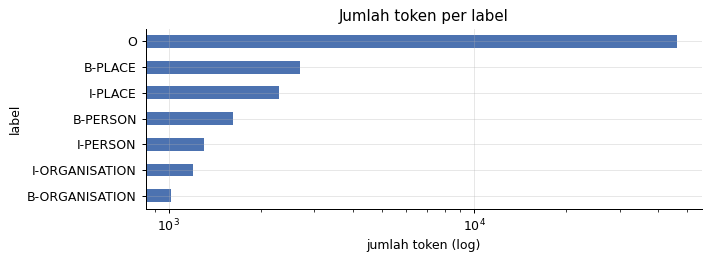

In [10]:
from collections import Counter  # noqa: E402

tag_counts = Counter(tag for _, tags in train for tag in tags)
lengths = pd.Series([len(tokens) for tokens, _ in train])
train_vocab = {w.lower() for tokens, _ in train for w in tokens}
test_words = [w.lower() for tokens, _ in test for w in tokens]
unseen = np.mean([w not in train_vocab for w in test_words])
truncated = float((lengths > 120).mean())
print(
    f"panjang kalimat median={lengths.median():.0f} | p95={lengths.quantile(0.95):.0f} | maks={lengths.max()}"
)
print(
    f"kata test yang tidak ada di latih: {unseen:.1%} | kalimat terpotong pada 120 token: {truncated:.1%}"
)

tag_table = pd.Series(tag_counts).sort_values()
fig, ax = plt.subplots(figsize=(8, max(3, 0.25 * len(tag_table))))
tag_table.plot.barh(ax=ax, color="#4C72B0", logx=True)
ax.set(title="Jumlah token per label", xlabel="jumlah token (log)", ylabel="label")
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| 11,7% kata test baru | Pakai transformer, bukan hanya fitur kata |
| Huruf besar jadi petunjuk kuat | Kapitalisasi tidak diubah |
| Hanya 0,4% kalimat terpotong pada 120 token | Batas 120 token cukup |

## 5. Preprocessing

Data sudah berupa token. Huruf besar dan tanda baca **tidak** diubah, karena sering menjadi petunjuk
kuat. Pembagian subtoken dan penyelarasan label dikerjakan oleh `encode_tokens`.

In [11]:
labels = sorted({tag for _, tags in train + valid + test for tag in tags})
y_valid = [tags for _, tags in valid]
y_test = [tags for _, tags in test]
print(f"jumlah label: {len(labels)}")

jumlah label: 7


## 6. Validasi

Dataset sudah menyediakan split valid dan test. Pemilihan model memakai valid, dan test hanya untuk laporan.
Metrik utamanya F1 tingkat span, jadi entitas baru dianggap benar kalau batas dan jenisnya tepat.

In [12]:
results: list[dict] = []


def record(name: str, pred_valid, pred_test) -> None:
    valid_scores = span_scores(y_valid, pred_valid)
    test_scores = span_scores(y_test, pred_test)
    results.append(
        {
            "model": name,
            "f1_valid": valid_scores["f1"],
            "f1_test": test_scores["f1"],
            "precision_test": test_scores["precision"],
            "recall_test": test_scores["recall"],
        }
    )
    print(results[-1])

## 7. Baseline

Regresi logistik per token dengan fitur kata. Sering sudah cukup kuat untuk label yang mudah.

In [13]:
with stage("baseline"):
    base_valid, base_test = token_baseline(train, valid), token_baseline(train, test)
record("baseline_fitur", base_valid, base_test)

[waktu] baseline: 36 detik
{'model': 'baseline_fitur', 'f1_valid': 0.4931, 'f1_test': 0.4947, 'precision_test': 0.4802, 'recall_test': 0.5102}


## 8. Model Utama

Transformer token classification. Di mode penuh beberapa seed digabung dengan suara terbanyak per token.

In [14]:
def majority_vote(all_preds: list[list[list[str]]]) -> list[list[str]]:
    voted = []
    for sentence_preds in zip(*all_preds):
        voted.append([Counter(tags).most_common(1)[0][0] for tags in zip(*sentence_preds)])
    return voted


with stage("transformer"):
    runs_valid, runs_test = [], []
    if USE_PRETRAINED:
        for model_name, seed in SETTINGS["model_runs"]:
            pred_valid, pred_test = train_token_model(
                model_name, train, [valid, test], labels, SETTINGS["epochs"], seed
            )
            runs_valid.append(pred_valid)
            runs_test.append(pred_test)
        main_valid, main_test = majority_vote(runs_valid), majority_vote(runs_test)
    else:
        main_valid, main_test = base_valid, base_test
record("model_utama", main_valid, main_test)

[waktu] transformer: 297 detik
{'model': 'model_utama', 'f1_valid': 0.7979, 'f1_test': 0.787, 'precision_test': 0.7669, 'recall_test': 0.8081}


## 9. Post-processing

Perbaiki urutan BIO yang tidak sah. Tanpa ini, label `I-` tanpa awalan bisa menghapus entitas.

In [15]:
final_valid = [repair_bio(tags) for tags in main_valid]
final_test = [repair_bio(tags) for tags in main_test]
record("model_utama_plus_perbaikan_bio", final_valid, final_test)

{'model': 'model_utama_plus_perbaikan_bio', 'f1_valid': 0.7979, 'f1_test': 0.787, 'precision_test': 0.7669, 'recall_test': 0.8081}


## 10. Post-analysis

**Tabel perbandingan.**

In [16]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,f1_valid,f1_test,precision_test,recall_test
0,baseline_fitur,0.4931,0.4947,0.4802,0.5102
1,model_utama,0.7979,0.7870,0.7669,0.8081
2,model_utama_plus_perbaikan_bio,0.7979,0.7870,0.7669,0.8081


**Skor per jenis.** Jenis mana yang paling lemah.

In [17]:
def per_type_scores(true_seqs, pred_seqs) -> pd.DataFrame:
    def kind_of(tag: str) -> str:
        return "O" if tag == "O" else (tag.partition("-")[2] or "frasa")

    def keep_only(seq: list[str], kind: str) -> list[str]:
        return [t if kind_of(t) == kind else "O" for t in seq]

    kinds = sorted({kind_of(tag) for tags in true_seqs for tag in tags} - {"O"})
    rows = []
    for kind in kinds:
        scores = span_scores(
            [keep_only(s, kind) for s in true_seqs], [keep_only(s, kind) for s in pred_seqs]
        )
        support = sum(len(extract_spans(keep_only(s, kind))) for s in true_seqs)
        rows.append({"jenis": kind, "jumlah": support, **scores})
    return pd.DataFrame(rows).sort_values("jumlah", ascending=False).head(30)


per_type_scores(y_test, final_test)

,jenis,jumlah,precision,recall,f1
2,PLACE,357,0.8292,0.8431,0.8361
1,PERSON,207,0.8111,0.8502,0.8302
0,ORGANISATION,124,0.5448,0.6371,0.5874


**Contoh kalimat yang salah.**

In [18]:
rows = []
for (tokens, _), truth, pred in zip(test, y_test, final_test):
    if truth != pred:
        rows.append(
            {
                "teks": " ".join(tokens)[:80],
                "asli": sorted(extract_spans(truth))[:3],
                "prediksi": sorted(extract_spans(pred))[:3],
            }
        )
    if len(rows) == 6:
        break
pd.DataFrame(rows)

,teks,asli,prediksi
0,"Pada tanggal 6 Februari 1976 , wakil ketua Lockheed Corporation memberitahu subk","[(8, 10, ORGANISATION), (13, 14, PLACE), (27, 28, ORGANISATION)]","[(8, 10, ORGANISATION), (13, 14, PLACE), (15, 16, PERSON)]"
1,"Awak pesawat yang terdiri atas pilot Ardy Tedjo , kopilot H Ribuan dan dua awak","[(6, 8, PERSON), (10, 12, PERSON), (16, 18, PERSON)]","[(6, 8, PERSON), (16, 18, PERSON), (19, 20, PERSON)]"
2,"Sebagai penutup tahun 1999 , Glay manggung bersama Luna Sea dalam pertarungan an","[(5, 6, ORGANISATION), (8, 10, ORGANISATION), (15, 17, ORGANISATION)]","[(5, 6, PERSON), (8, 10, PERSON), (15, 17, ORGANISATION)]"
3,Terdapat sebuah terminal bus antar kota sebagai titik penghubung antara Kota Sol,"[(13, 15, PLACE), (16, 18, PLACE)]","[(10, 12, PLACE), (13, 15, PLACE), (16, 18, PLACE)]"
4,Pertamina UP II Dumai di Sei Pakning sebagai bandar udara khusus yang dapat mela,"[(0, 1, ORGANISATION), (3, 4, PLACE), (5, 7, PLACE)]","[(0, 4, ORGANISATION), (5, 7, PLACE)]"
5,"Dia juga yang memperkenalkan gerakan yang di kenal sebagai "" flip - flap "" , yan","[(21, 22, PERSON), (23, 25, PERSON), (28, 30, PERSON)]","[(21, 22, PERSON), (23, 27, PERSON), (28, 30, PERSON)]"


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [19]:
pd.DataFrame({"id": range(len(final_test)), "tags": [" ".join(t) for t in final_test]}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "ner",
    len(train),
    {r["model"]: {"valid": r["f1_valid"], "test": r["f1_test"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=ner mode=penuh n_rows=1672 total_detik=349 gpu=True
{
 "baseline_fitur": {
  "valid": 0.4931,
  "test": 0.4947
 },
 "model_utama": {
  "valid": 0.7979,
  "test": 0.787
 },
 "model_utama_plus_perbaikan_bio": {
  "valid": 0.7979,
  "test": 0.787
 }
}


**Poin untuk presentasi**

- F1 test 0,787, sedangkan baseline fitur 0,4947.
- ORGANISATION paling sulit (0,5874), dibanding PLACE 0,8361 dan PERSON 0,8302.
- Perbaikan BIO tidak mengubah skor pada data ini, jadi bisa dilewati kalau waktu mepet.
- Teks MBG biasanya huruf kecil semua, jadi skor bisa turun dibanding teks berita ini.